### Case 1: BERT in qqp

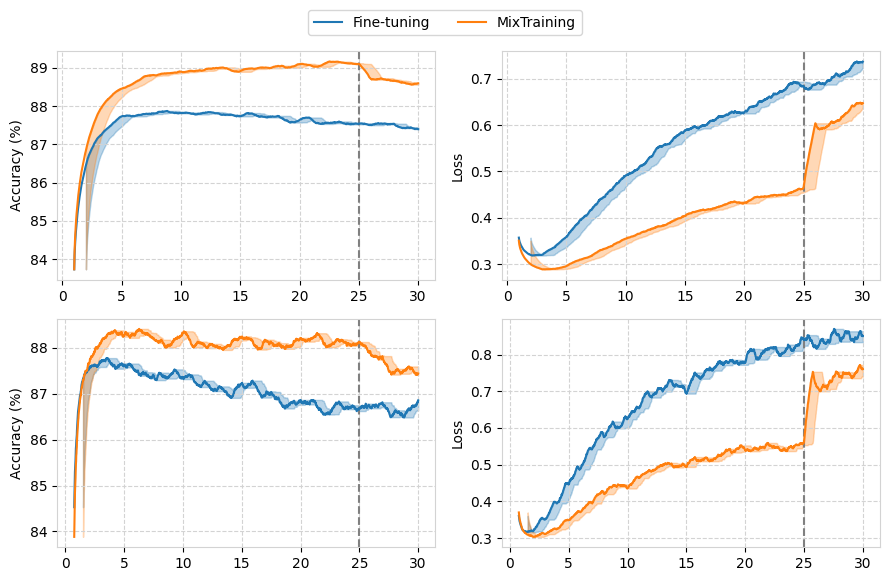

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

qqp_accuracy = pd.read_csv("results/qqp/bert-base-cased/wandb_export_2024-02-01T14_42_16.175-08_00.csv")
qqp_loss = pd.read_csv("results/qqp/bert-base-cased/wandb_export_2024-02-01T14_45_36.382-08_00.csv")
qnli_accuracy = pd.read_csv("results/qnli/bert-base-cased/wandb_export_2024-01-26T11_59_44.961-08_00.csv")
qnli_loss = pd.read_csv("results/qnli/bert-base-cased/wandb_export_2024-01-26T11_59_49.877-08_00.csv")

task_metric = {
    'qqp': {
        'accuracy': qqp_accuracy,
        'loss': qqp_loss,
    },
    'qnli': {
        'accuracy': qnli_accuracy,
        'loss': qnli_loss,
    },
}
model = 'bert-base-cased'
fig, axes = plt.subplots(2, 2, figsize=(9, 5.5))
window_sizes = [100, 50]  # This defines the smoothing window
transforms = {'accuracy': 'Accuracy (%)', 'f1': 'F-1 (%)', 'loss': 'Loss'}
# set grey grid
for i, task in enumerate(task_metric.keys()):
    window_size = window_sizes[i]
    task_metrics = task_metric[task]
    for j, (metric, scale, yrange,) in enumerate([
        ('accuracy', 100, None), 
        ('loss', 1, None),
    ]):
        metric_res = task_metrics[metric]
        indices = metric_res[metric_res['train/epoch'] <= 30].index
        ax = axes[i][j]
        for spine in ax.spines.values():
            spine.set_edgecolor('lightgrey')
        ax.grid(color='lightgrey', linestyle='dashed')
        ax.axvline(x=25, color='grey', linestyle='--')
        # Smooth the data using rolling mean
        smooth_fine_tuning = metric_res[f'run_glue_{task}_{model}_mix-0 - eval/{metric}'][indices].rolling(window=window_size).mean() * scale
        smooth_mix_training = metric_res[f'run_glue_{task}_{model}_mix-25 - eval/{metric}'][indices].rolling(window=window_size).mean() * scale
        epochs = metric_res['train/epoch'][indices]
        # ax.plot(metric_res['train/epoch'][indices], smoothed_fine_tuning, label='Fine-tuning')
        # ax.plot(metric_res['train/epoch'][indices], smoothed_mix_training, label='MixTraining')
        # lightblue = '#1f77b4', lightorange = '#ff7f0e'
        ax.plot(epochs, smooth_fine_tuning, label='Fine-tuning')
        ax.fill_between(epochs, smooth_fine_tuning.rolling(window=window_size).min(), smooth_fine_tuning.rolling(window=window_size).max(), color='#1f77b4', alpha=0.3)
        ax.plot(epochs, smooth_mix_training, label='MixTraining')
        ax.fill_between(epochs, smooth_mix_training.rolling(window=window_size).min(), smooth_mix_training.rolling(window=window_size).max(), color='#ff7f0e', alpha=0.3)
        # ax.set_title(transforms[metric])
        ax.set_ylabel(transforms[metric])
        if yrange is not None:
            ax.set_ylim(yrange)
    # ax.legend()
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2,  bbox_to_anchor=(0.5, 1.06))
plt.tight_layout()
plt.savefig(f'results/{model}_mix_training.pdf', bbox_inches='tight')
plt.show()

### Case 2: BERT in qnli

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


accuracy.head()

task = 'qnli'
model = 'bert-base-cased'
fig, axes = plt.subplots(1, 2, figsize=(9, 2.7))
transforms = {'accuracy': 'Accuracy (%)', 'f1': 'F-1 (%)', 'loss': 'Loss'}
# set grey grid
for i, (metric, metric_res, scale, yrange) in enumerate([
    ('accuracy', accuracy, 100, None), 
    # ('None', accuracy, 100), 
    ('loss', loss, 1.0, None), 
]):
    ax = axes[i]
    # ax.grid(color='grey', linestyle='-', linewidth=0.25, alpha=0.5)
    # Get the indices of those epoch <= 30
    indices = metric_res[metric_res['train/epoch'] <= 30].index
    ax.axvline(x=25, color='lightgrey', linestyle='--')
    smoothed_0 = metric_res[f'run_glue_{task}_{model}_mix-0 - eval/{metric}'].rolling(window=50).mean()
    ax.plot(metric_res['train/epoch'][indices], smoothed_0[indices] * scale, label='Fine-tuning')
    smoothed_25 = metric_res[f'run_glue_{task}_{model}_mix-25 - eval/{metric}'].rolling(window=50).mean()
    ax.plot(metric_res['train/epoch'][indices], smoothed_25[indices] * scale, label='MixTraining')
    # ax.set_title(transforms[metric])
    ax.set_ylabel(transforms[metric])
    if yrange is not None:
        ax.set_ylim(yrange)
    # ax.legend()
    
# Use a common legend
plt.savefig(f'results/{task}/{model}_{task}_mix_training.pdf', bbox_inches='tight')
plt.show()

### Get maximum accuracy

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

model = 'bert-base-cased'
all_acc_0, all_acc_25 = [], []
task = 'qnli'
print()
print(task)
file1 = f"results/{task}/{model}/wandb_export_2024-01-26T11_59_44.961-08_00.csv"
accuracy = pd.read_csv(file1)
best_acc_0 = max(accuracy[f'run_glue_{task}_{model}_mix-0 - eval/accuracy'])
print(best_acc_0)
best_acc_25 = max(accuracy[f'run_glue_{task}_{model}_mix-25 - eval/accuracy'])
print(best_acc_25)
all_acc_0.append(best_acc_0)
all_acc_25.append(best_acc_25)

task = 'sst2'
print()
print(task)
file1 = f"results/{task}/{model}/wandb_export_2024-01-27T11_16_52.827-08_00.csv"
accuracy = pd.read_csv(file1)
best_acc_0 = max(accuracy[f'run_glue_{task}_{model}_mix-0 - eval/accuracy'])
print(best_acc_0)
best_acc_25 = max(accuracy[f'run_glue_{task}_{model}_mix-25 - eval/accuracy'])
print(best_acc_25)
all_acc_0.append(best_acc_0)
all_acc_25.append(best_acc_25)

# task = 'mrpc'
# print()
# print(task)
# file1 = f"results/{task}/{model}/wandb_export_2024-01-27T11_19_48.066-08_00.csv"
# accuracy = pd.read_csv(file1)
# best_acc_0 = max(accuracy[f'run_glue_{task}_{model}_mix-0 - eval/accuracy'])
# print(best_acc_0)
# best_acc_25 = max(accuracy[f'run_glue_{task}_{model}_mix-25 - eval/accuracy'])
# print(best_acc_25)
# all_acc_0.append(best_acc_0)
# all_acc_25.append(best_acc_25)

# task = 'rte'
# print()
# print(task)
# file1 = f"results/{task}/{model}/wandb_export_2024-01-28T10_40_04.925-08_00.csv"
# accuracy = pd.read_csv(file1)
# best_acc_0 = max(accuracy[f'run_glue_{task}_{model}_mix-0 - eval/accuracy'])
# print(best_acc_0)
# best_acc_25 = max(accuracy[f'run_glue_{task}_{model}_mix-25 - eval/accuracy'])
# print(best_acc_25)
# all_acc_0.append(best_acc_0)
# all_acc_25.append(best_acc_25)

task = 'qqp'
print()
print(task)
file1 = f"results/{task}/{model}/wandb_export_2024-01-24T21_22_39.565-08_00.csv"
accuracy = pd.read_csv(file1)
best_acc_0 = max(accuracy[f'run_glue_{task}_{model}_mix-0 - eval/accuracy'])
print(best_acc_0)
best_acc_25 = max(accuracy[f'run_glue_{task}_{model}_mix-25 - eval/accuracy'])
print(best_acc_25)
all_acc_0.append(best_acc_0)
all_acc_25.append(best_acc_25)

task = 'mnli'
print()
print(task)
file1 = f"results/{task}/{model}/wandb_export_2024-01-30T16_18_09.346-08_00.csv"
accuracy = pd.read_csv(file1)
best_acc_0 = max(accuracy[f'run_glue_{task}_{model}_mix-0 - eval/accuracy'])
print(best_acc_0)
best_acc_25 = max(accuracy[f'run_glue_{task}_{model}_mix-25 - eval/accuracy'])
print(best_acc_25)
all_acc_0.append(best_acc_0)
all_acc_25.append(best_acc_25)

# Get average
print()
print('Average')
print(sum(all_acc_0) / len(all_acc_0))
print(sum(all_acc_25) / len(all_acc_25))

In [ ]:
model = 'gpt2'
all_acc_0, all_acc_25 = [], []
task = 'qnli'
print()
print(task)
file1 = f"results/{task}/{model}/wandb_export_2024-01-27T11_09_03.274-08_00.csv"
accuracy = pd.read_csv(file1)
best_acc_0 = max(accuracy[f'run_glue_{task}_{model}_mix-0 - eval/accuracy'])
print(best_acc_0)
best_acc_25 = max(accuracy[f'run_glue_{task}_{model}_mix-25 - eval/accuracy'])
print(best_acc_25)
all_acc_0.append(best_acc_0)
all_acc_25.append(best_acc_25)

task = 'sst2'
print()
print(task)
file1 = f"results/{task}/{model}/wandb_export_2024-01-27T11_28_46.535-08_00.csv"
accuracy = pd.read_csv(file1)
best_acc_0 = max(accuracy[f'run_glue_{task}_{model}_mix-0 - eval/accuracy'])
print(best_acc_0)
best_acc_25 = max(accuracy[f'run_glue_{task}_{model}_mix-25 - eval/accuracy'])
print(best_acc_25)
all_acc_0.append(best_acc_0)
all_acc_25.append(best_acc_25)

# task = 'mrpc'
# print()
# print(task)
# file1 = f"results/{task}/{model}/wandb_export_2024-01-26T11_33_02.821-08_00.csv"
# accuracy = pd.read_csv(file1)
# best_acc_0 = max(accuracy[f'run_glue_{task}_{model}_mix-0 - eval/accuracy'])
# print(best_acc_0)
# best_acc_25 = max(accuracy[f'run_glue_{task}_{model}_mix-25 - eval/accuracy'])
# print(best_acc_25)
# all_acc_0.append(best_acc_0)
# all_acc_25.append(best_acc_25)

# task = 'rte'
# print()
# print(task)
# file1 = f"results/{task}/{model}/wandb_export_2024-01-28T10_40_52.171-08_00.csv"
# accuracy = pd.read_csv(file1)
# best_acc_0 = max(accuracy[f'run_glue_{task}_{model}_mix-0 - eval/accuracy'])
# print(best_acc_0)
# best_acc_25 = max(accuracy[f'run_glue_{task}_{model}_mix-25 - eval/accuracy'])
# print(best_acc_25)
# all_acc_0.append(best_acc_0)
# all_acc_25.append(best_acc_25)

task = 'qqp'
print()
print(task)
file1 = f"results/{task}/{model}/wandb_export_2024-01-27T11_28_12.285-08_00.csv"
accuracy = pd.read_csv(file1)
best_acc_0 = max(accuracy[f'run_glue_{task}_{model}_mix-0 - eval/accuracy'])
print(best_acc_0)
best_acc_25 = max(accuracy[f'run_glue_{task}_{model}_mix-25 - eval/accuracy'])
print(best_acc_25)
all_acc_0.append(best_acc_0)
all_acc_25.append(best_acc_25)

task = 'mnli'
print()
print(task)
file1 = f"results/{task}/{model}/wandb_export_2024-01-30T16_15_57.734-08_00.csv"
accuracy = pd.read_csv(file1)
best_acc_0 = max(accuracy[f'run_glue_{task}_{model}_mix-0 - eval/accuracy'])
print(best_acc_0)
best_acc_25 = max(accuracy[f'run_glue_{task}_{model}_mix-25 - eval/accuracy'])
print(best_acc_25)
all_acc_0.append(best_acc_0)
all_acc_25.append(best_acc_25)

# Get average
print()
print('Average')
print(sum(all_acc_0) / len(all_acc_0))
print(sum(all_acc_25) / len(all_acc_25))

### Case study: MLM, CLM, Sentiment Analysis, NLI

### Sentiment Analysis

In [1]:
# Case study on the qqp dataset
from datasets import load_dataset

dataset = load_dataset("glue", "sst2")
dataset = dataset['train']
print(dataset)
print(dataset[0])

from modeling_bert import BertForSequenceClassification
model_0 = BertForSequenceClassification.from_pretrained("results/sst2/bert-base-cased/mix-0").to('cuda')
model_25 = BertForSequenceClassification.from_pretrained("results/sst2/bert-base-cased/mix-25").to('cuda')

from tqdm import tqdm
from transformers import AutoTokenizer

# Show some examples where model_0 is wrong but model_25 is correct
tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")
# for i in tqdm(range(len(dataset))):
#     text = dataset[i]['sentence']
#     label = dataset[i]['label']
#     encoded = tokenizer(text, return_tensors='pt', padding=True, truncation=True).to('cuda')
#     logits_0 = model_0(**encoded).logits
#     logits_25 = model_25(**encoded).logits
#     pred_0 = logits_0.argmax().item()
#     pred_25 = logits_25.argmax().item()
#     if pred_0 != label and pred_25 == label:
#         print(text)
#         print(f"model_0: {pred_0}, model_25: {pred_25}, label: {label}")
#         print()

/home/yli927/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset({
    features: ['sentence', 'label', 'idx'],
    num_rows: 67349
})
{'sentence': 'hide new secretions from the parental units ', 'label': 0, 'idx': 0}


In [2]:
# Case study on the qqp dataset
from datasets import load_dataset

raw_dataset = load_dataset("glue", "qnli")
dataset = raw_dataset['train']
print(dataset)
print(dataset[0])
label_list = dataset.unique("label")
label_list.sort()
label_to_id = {v: i for i, v in enumerate(label_list)}
max_seq_length = 128
max_seq_length = min(max_seq_length, tokenizer.model_max_length)

def tokenize(examples):
    args = (
        (examples['question'], examples['sentence']) 
    )
    result = tokenizer(
        *args, 
        padding=False, 
        max_length=max_seq_length, 
        truncation=True,
        # We use this option because MyDataCollator (see below) is more efficient when it
        # receives the `special_tokens_mask`.
        return_special_tokens_mask=False, 
    )
    # Map labels to IDs (not necessary for GLUE tasks)
    result["label"] = [(label_to_id[l] if l != -1 else -1) for l in examples["label"]]
    return result

tokenized_dataset = dataset.map(tokenize, batched=True, remove_columns=dataset.column_names)
tokenized_dataset

Dataset({
    features: ['question', 'sentence', 'label', 'idx'],
    num_rows: 104743
})
{'question': 'When did the third Digimon series begin?', 'sentence': 'Unlike the two seasons before it and most of the seasons that followed, Digimon Tamers takes a darker and more realistic approach to its story featuring Digimon who do not reincarnate after their deaths and more complex character development in the original Japanese.', 'label': 1, 'idx': 0}


Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 104743
})

In [ ]:
import torch
from modeling_gpt2 import GPT2ForSequenceClassification
from transformers import AutoTokenizer
from tqdm import tqdm

model_0 = GPT2ForSequenceClassification.from_pretrained("results/qnli/gpt2/mix-0").to('cuda')
model_25 = GPT2ForSequenceClassification.from_pretrained("results/qnli/gpt2/mix-25/checkpoint-326500").to('cuda')
model_0.eval()
model_25.eval()
case = 0
for i, instance in tqdm(enumerate(dataset), total=len(dataset)):
    # prepare batch
    args = (
        (instance['question'], instance['sentence']) 
    )
    encoded = tokenizer(*args, padding=False, max_length=max_seq_length, truncation=True, return_tensors='pt').to('cuda')
    # forward
    with torch.no_grad():
        logits_0 = model_0(**encoded).logits
        logits_25 = model_25(**encoded).logits
    pred_0 = logits_0.argmax().item()
    pred_25 = logits_25.argmax().item()
    label = label_to_id[instance['label']]
    
    if pred_0 != label and pred_25 == label:
        print(f"case {case}")
        print(f"model_0: {pred_0}, model_25: {pred_25}, label: {label}")
        print(f"question: {instance['question']}")
        print(f"sentence: {instance['sentence']}")
        print()
        case += 1
        
    if case == 10:
        break
    

In [25]:
import torch
from modeling_bert import BertForSequenceClassification

def mlm_forward(model: BertForSequenceClassification, encoded: torch.Tensor):
    outputs = model.bert(encoded)
    sequence_output = outputs[0]
    prediction_scores = model.mlm_head(sequence_output)
    return prediction_scores

for i in range(10):
    text = dataset[i]['sentence']
    tokenized_text = tokenizer.tokenize(text)
    # Random select two mask tokens for each example
    mask_ids = torch.randint(0, len(tokenized_text), (2,))
    labels = []
    for mask_id in mask_ids:
        tokenized_text[mask_id] = tokenizer.mask_token
        labels.append(tokenizer.tokenize(text)[mask_id])
        
    mask_text = tokenizer.convert_tokens_to_string(tokenized_text)
    indexed_tokens = tokenizer.convert_tokens_to_ids(tokenized_text)
    token_tensor = torch.tensor([indexed_tokens]).to('cuda')

    logits_0 = mlm_forward(model_0, token_tensor)
    logits_25 = mlm_forward(model_25, token_tensor)
    pred_0 = logits_0[:, mask_ids].argmax(dim=-1).tolist()
    pred_25 = logits_25[:, mask_ids].argmax(dim=-1).tolist()
    
    with torch.no_grad():
        logits_0 = model_0(token_tensor).logits
        logits_25 = model_25(token_tensor).logits
    pred_0_cls = logits_0.argmax().item()
    pred_25_cls = logits_25.argmax().item()
    label = label_to_id[dataset[i]['label']]

    print("Original text: ", text)
    print("Masked text: ", mask_text)
    print(tokenizer.convert_ids_to_tokens(pred_0[0]),
          tokenizer.convert_ids_to_tokens(pred_25[0]), 
          labels)
    print("Cls result: ", pred_0_cls, pred_25_cls, label)

Original text:  Unlike the two seasons before it and most of the seasons that followed, Digimon Tamers takes a darker and more realistic approach to its story featuring Digimon who do not reincarnate after their deaths and more complex character development in the original Japanese.
Masked text:  Unlike the two seasons before it and most of the seasons that followed, Digimon Tamers takes a darker and more realistic approach to its story featuring Digimon [MASK] do not reincarnate after their deaths and more complex character development [MASK] the original Japanese.
['Netherlands', 'Netherlands'] ['than', 'who'] ['in', 'who']
Cls result:  1 1 1
Original text:  When MANPADS is operated by specialists, batteries may have several dozen teams deploying separately in small sections; self-propelled air defence guns may deploy in pairs.
Masked text:  When MANPADS is [MASK] by specialists, batteries may have several dozen teams deploying separately in small sections ; [MASK] - propelled air de

In [ ]:
from modeling_gpt2 import GPT2ForSequenceClassification
from transformers import GPT2LMHeadModel
# model_0 = GPT2ForSequenceClassification.from_pretrained("results/sst2/gpt2/mix-0").to('cuda')
# model_25 = GPT2ForSequenceClassification.from_pretrained("results/sst2/gpt2/mix-25").to('cuda')
model_0 = GPT2LMHeadModel.from_pretrained("results/sst2/gpt2/mix-0")
model_25 = GPT2LMHeadModel.from_pretrained("results/sst2/gpt2/mix-25")
# model_0 = GPT2LMHeadModel.from_pretrained("gpt2")
# model_25 = GPT2LMHeadModel.from_pretrained("gpt2")

model_0.eval()
model_25.eval()

def clm_forward(model: GPT2ForSequenceClassification, encoded: torch.Tensor):
    outputs = model.transformer(encoded)
    sequence_output = outputs[0]
    logits = model.lm_head(sequence_output)
    return logits

for i in tqdm(range(10)):

    text = dataset[i]['sentence']
    tokenized_text = tokenizer.tokenize(text)
    # query_texts, label_texts = tokenized_text[:-5], tokenized_text[-5:]
    query_texts = tokenized_text
    query_tensor = torch.tensor([tokenizer.convert_tokens_to_ids(query_texts)])

    # logits_0 = clm_forward(model_0, query_tensor)
    # logits_25 = clm_forward(model_25, query_tensor) # 1 X T X V
    logits_0 = model_0(query_tensor).logits # 1 X T X V
    logits_25 = model_25(query_tensor).logits # 1 X T X V

    pred_0 = logits_0.argmax(dim=-1).tolist()[0]
    # Sample the predicted tokens
    pred_25 = logits_25.argmax(dim=-1).tolist()[0]
    labels = tokenizer.tokenize(text)[1:]
    
    # calculate the jaccard similarity (IoU) between the prediction and the label
    # pred_0 = set(pred_0)
    # pred_25 = set(pred_25)
    # labels = set(labels)
    # iou_0 = len(pred_0.intersection(labels)) / len(pred_0.union(labels))
    # iou_25 = len(pred_25.intersection(labels)) / len(pred_25.union(labels))
    
    
    print("Original text: ", text)
    print("Mix-0: {}\nMix-25: {}\nlabels: {}".format(
        tokenizer.convert_ids_to_tokens(pred_0, skip_special_tokens=True), 
        tokenizer.convert_ids_to_tokens(pred_25, skip_special_tokens=True),
        labels))
    
    print()

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer

top_k = 100
tokenizer = AutoTokenizer.from_pretrained("results/sst2/gpt2/mix-0")
model_0 = AutoModelForCausalLM.from_pretrained("results/sst2/gpt2/mix-0")
text = 'Demonstrates that the director of such hollywood blockbusters as patriot games can still turn out a small, personal film with an emotional wallop.'
inputs = tokenizer(text, return_tensors='pt')
# outputs = model_0.generate(inputs['input_ids'], max_length=50, do_sample=True, top_k=50, top_p=0.95, temperature=0.7)
outputs = model_0(inputs['input_ids']) # 1 X T
logits = outputs.logits
# top-10 sampling
values, indices = logits.topk(top_k, dim=-1) # 1 X T X 10
preds = []
gts = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0][1:].tolist())
print(f"Ground truth ({len(gts)}): {[(i, tok) for i, tok in enumerate(gts)]}")
for i, input_id in enumerate(inputs['input_ids'][0][1:]):
    # print(f"input_id: {input_id}, top_10: {indices[0][i].tolist()}")
    if input_id in indices[0][i].tolist():
        preds.append(input_id)
    else:
        preds.append(indices[0][i][0].item())
pred_text = tokenizer.convert_ids_to_tokens(preds)
print(f"Mix-0 ({len(pred_text)}): {[(i, tok) for i, tok in enumerate(pred_text)]}")   


tokenizer = AutoTokenizer.from_pretrained("results/sst2/gpt2/mix-25")
model_0 = AutoModelForCausalLM.from_pretrained("results/sst2/gpt2/mix-25")
text = 'Demonstrates that the director of such hollywood blockbusters as patriot games can still turn out a small, personal film with an emotional wallop.'
inputs = tokenizer(text, return_tensors='pt')
# outputs = model_0.generate(inputs['input_ids'], max_length=50, do_sample=True, top_k=50, top_p=0.95, temperature=0.7)
outputs = model_0(inputs['input_ids']) # 1 X T
logits = outputs.logits
# top-10 sampling
values, indices = logits.topk(top_k, dim=-1) # 1 X T X 10
preds = []
for i, input_id in enumerate(inputs['input_ids'][0][1:]):
    # print(f"input_id: {input_id}, top_10: {indices[0][i].tolist()}")
    if input_id in indices[0][i].tolist():
        preds.append(input_id)
    else:
        preds.append(indices[0][i][0].item())
pred_text = tokenizer.convert_ids_to_tokens(preds)
print(f"Mix-25 ({len(pred_text)}): {[(i, tok) for i, tok in enumerate(pred_text)]}")   

In [ ]:
inputs['input_ids']

In [ ]:
### t-SNE visualization

In [ ]:
import numpy as np
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Function to extract features from a model
def extract_features(model, dataloader):
    features = []
    labels = []
    with torch.no_grad():
        for data in dataloader:
            inputs, label = data[0].to(device), data[1].to(device)
            output = model(inputs)  # Modify this line if your model has a specific feature layer
            features.extend(output.cpu().numpy())
            labels.extend(label.cpu().numpy())
    return np.array(features), np.array(labels)

# Extract features and labels
features, labels = extract_features(mae_mix, val_dataloader)
# Apply t-SNE to reduce dimensionality to 2D for visualization
tsne = TSNE(n_components=2, random_state=0)
reduced_features = tsne.fit_transform(features)

if args.dataset == 'cifar10':
    class_num = 10
elif args.dataset == 'tinyimagenet':
    class_num = 200

# Plot t-SNE results with labels
plt.figure(figsize=(10, 6))
for i in range(class_num):  # CIFAR-10 has 10 classes
    indices = np.where(labels == i)[0]
    plt.scatter(reduced_features[indices, 0], reduced_features[indices, 1], label=str(i), s=8)
plt.legend(loc='best')
plt.title('t-SNE visualization of {} Features'.format(args.dataset))
plt.xlabel('t-SNE dimension 1')
plt.ylabel('t-SNE dimension 2')
plt.savefig('tsne.png')